# 5.1 observify, simply

Turns a clean (SSD) and a contaminated (facular band) actress spectrum into HARPS-resolution spectra and forms their spectral ratio (SRA) as in Costes et al. 2026 ([arXiv:2607.06339](https://arxiv.org/abs/2607.06339)). One cell per step, in order:

1. settings
2. load the two fluxes
3. convolve to R = 115,000
3b. resample onto the observed pixels (`target_wavelength_file`)
4. SNR array and noise
5. normalise each spectrum to its peak
6. ratio
6b. flatten: divide the ratio by its 15-pixel Gaussian smoothing
7. plots
8. SRA residual at SNR 200, 500, 1000 and 3000

All wavelengths are air, as HARPS records them; the simulation's vacuum wavelengths are converted on loading. Run from `actress_highres/actress/`.


In [13]:
# ===== 1. settings =====
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

speed_of_light = 299792.458   # km/s

# Spectra simulated in 1_gridsearch (real SSD + 200G facula, v_eq 4000 m/s); names are <geometry>_ff<ff>_i<inc>
cache_file = './outputs/gridsearch/1_gridsearch_v4000_res3d5_res2d200_4300.1_4399.9_randomseed0_incs0-90x10.npz'
contaminated_name = 'equatorial_ff0.10_i90'
clean_name = 'quiet_i90'   # the clean star at the SAME inclination

# HARPS: R = 115,000 (Mayor et al. 2003, The Messenger 114, 20;
# https://www.hq.eso.org/sci/facilities/lasilla/instruments/harps/science/papers/harps_mess114.pdf)
resolution = 115000   # spectra stay on the simulation grid, not resampled onto HARPS pixels
target_wavelength_file = './jean_data/Dana_SDA_HD146233_G2V_order21.txt'   # HARPS e2ds order 21 pixels, A, air


# Morton 2000: https://doi.org/10.1086/317349 ; VALD's formula page: https://www.astro.uu.se/valdwiki/Air-to-vacuum%20conversion
def vacuum_to_air(wavelength_vacuum):
    """Air wavelength (A) from vacuum (A): Morton 2000, ApJS 130, 403 (IAU standard), the formula VALD gives."""
    s_squared = (1e4 / wavelength_vacuum) ** 2   # um^-2
    refractive_index = 1 + 0.0000834254 + 0.02406147 / (130 - s_squared) + 0.00015998 / (38.9 - s_squared)
    return wavelength_vacuum / refractive_index


# Noise: snr is the SNR per HARPS pixel (target_wavelength_file) at the continuum (peak flux), at these wavelengths.
# Per pixel, not per resolution element: HARPS samples each spectral element with 3.2 pixels (Mayor et al. 2003,
# Table 1), so the SNR per resolution element would be ~sqrt(3.2) = 1.8x higher
snr = 1000                  # choose 200-3000
seed_active = 1             # noise seed for the contaminated (active) spectrum
seed_inactive = 2           # noise seed for the clean (inactive) spectrum
if not 200 <= snr <= 3000:
    raise ValueError(f"snr = {snr} is outside 200-3000")

# Flattening (step 6b). Paper (Sec. 2.2, p. 5, col. 1): "applying a Gaussian filter with sigma = 15 pixels, and divided
# the ratio spectra by this smooth fit to flatten the remaining residuals"
flatten_sigma = 15   # HARPS pixels (~12 km/s)

# The paper's Fig. 1 window and its features (Fe I 4375.9, 4378.3, 4379.2 A air); features are the quiet star's
# line minima (vacuum 4377.159, 4379.514, 4380.460 A) converted to air
plot_window = (4367.50, 4382.50)                                                   # A, air
paper_features = {'Fe I 4375.9': 4375.929, '4378.3': 4378.284, '4379.2': 4379.229}   # A, air

def mark_paper_features(ax):
    for feature_wavelength in paper_features.values():
        ax.axvline(feature_wavelength, color='tab:blue', linestyle=':', linewidth=0.8)

equatorial_ff0.10_i90 (visible ff 0.093) and quiet_i90: 11457 bins, 4298.96-4398.59 A


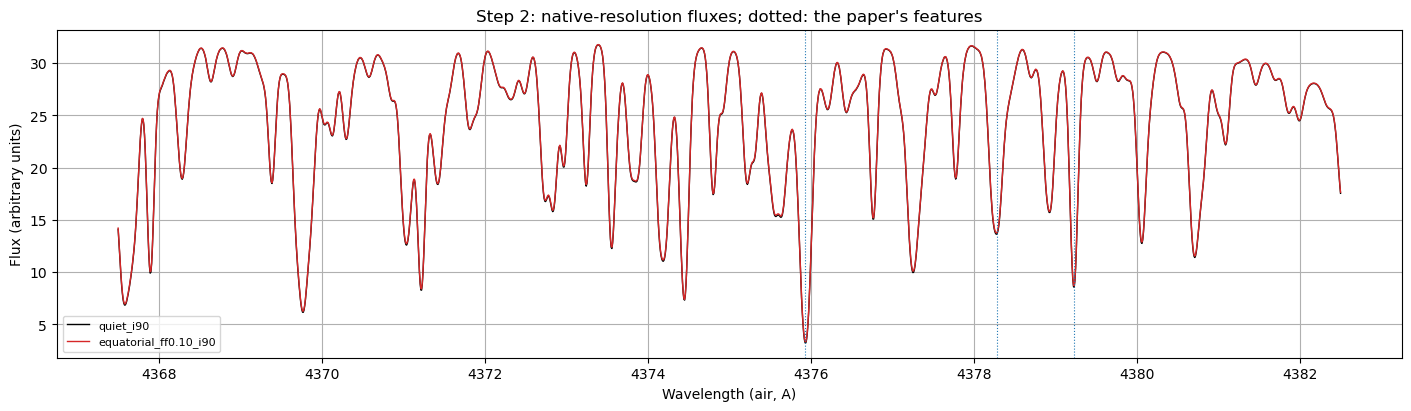

In [14]:
# ===== 2. load the two fluxes =====
cache = np.load(cache_file)
wavelength = cache[f'bins_{contaminated_name}']   # A, vacuum in the cache, log-uniform at R = 500,000
if not np.array_equal(wavelength, cache[f'bins_{clean_name}']):
    raise ValueError(f"{contaminated_name} and {clean_name} are on different bins: different inclinations?")
wavelength = vacuum_to_air(wavelength)   # A, air
flux_active = cache[f'spectrum_{contaminated_name}']   # arbitrary units
flux_inactive = cache[f'spectrum_{clean_name}']
for name, flux in ((contaminated_name, flux_active), (clean_name, flux_inactive)):
    if not np.all(np.isfinite(flux)) or np.any(flux <= 0):
        raise ValueError(f"{name}: non-finite or non-positive flux")
visible_ff = dict(zip(cache['run_names'], cache['visible_ffs']))[contaminated_name]
print(f"{contaminated_name} (visible ff {visible_ff:.3f}) and {clean_name}: {len(wavelength)} bins, "
      f"{wavelength[0]:.2f}-{wavelength[-1]:.2f} A")

in_window_native = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])
fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(wavelength[in_window_native], flux_inactive[in_window_native], color='k', linewidth=1, label=clean_name)
ax.plot(wavelength[in_window_native], flux_active[in_window_native], color='tab:red', linewidth=1, label=contaminated_name)
mark_paper_features(ax)
ax.set_xlabel('Wavelength (air, A)')
ax.set_ylabel('Flux (arbitrary units)')
ax.set_title('Step 2: native-resolution fluxes; dotted: the paper\'s features')
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

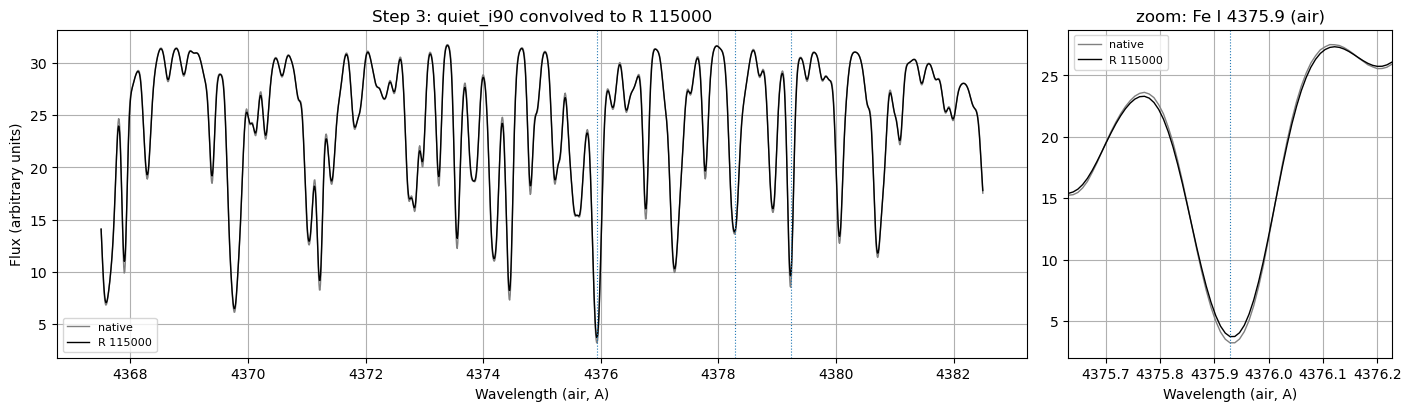

In [15]:
# ===== 3. convolve to R = 115,000 =====
# Gaussian convolution of FWHM reference_wavelength / R, converted to bins with the mean wavelength step
reference_wavelength = 4360   # A, air
convolution_fwhm = reference_wavelength / resolution   # A
convolution_sigma = convolution_fwhm / (2 * np.sqrt(2 * np.log(2)))   # A
wavelength_step = np.mean(np.diff(wavelength))   # A
convolution_sigma_bins = convolution_sigma / wavelength_step
convolved_active = gaussian_filter1d(flux_active, convolution_sigma_bins, mode='nearest')
convolved_inactive = gaussian_filter1d(flux_inactive, convolution_sigma_bins, mode='nearest')
# No edge trim: the outer ~6 bins at each end are averaged with mode='nearest' padding (SRA error < 1e-4)
#print(f"Convolution FWHM {convolution_fwhm * 1000:.2f} mA at {reference_wavelength} A = {convolution_sigma_bins * 2.3548:.2f} bins")

near_fe_native = np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.3
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True, gridspec_kw={'width_ratios': [3, 1]})
for ax, selection in zip(axes, (in_window_native, near_fe_native)):
    ax.plot(wavelength[selection], flux_inactive[selection], color='grey', linewidth=1, label='native')
    ax.plot(wavelength[selection], convolved_inactive[selection], color='k', linewidth=1, label=f'R {resolution}')
    mark_paper_features(ax)
    ax.set_xlabel('Wavelength (air, A)')
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Flux (arbitrary units)')
axes[0].set_title(f'Step 3: {clean_name} convolved to R {resolution}')
axes[1].set_title('zoom: Fe I 4375.9 (air)')
axes[1].set_xlim(wavelength[near_fe_native][0], wavelength[near_fe_native][-1])
plt.show()

11457 simulation bins -> 4095 pixels from ./jean_data/Dana_SDA_HD146233_G2V_order21.txt: 4345.72-4394.55 A, 10.0-13.9 mA wide


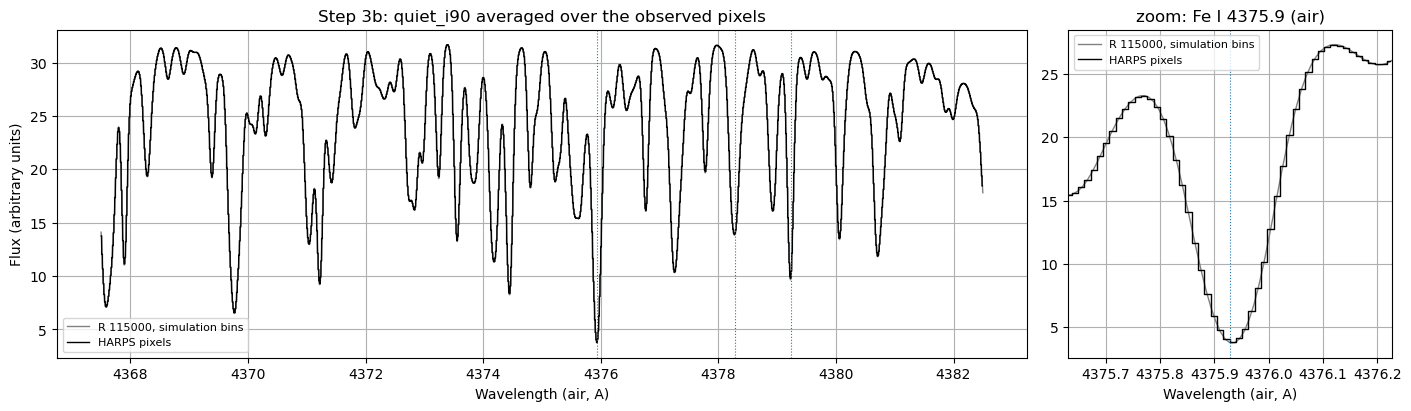

In [16]:
# ===== 3b. resample onto the observed pixels =====
# Convolve first, then bin: the line-spread function blurs the light before the detector samples it. Each observed
# pixel records the mean convolved flux over its extent (air). From here on, wavelength is the observed pixel grid.
def pixel_averaged(flux, wavelength_fine, pixel_centres):
    """Mean of flux over each pixel; edges are midpoints between centres, end pixels extended symmetrically."""
    midpoints = 0.5 * (pixel_centres[1:] + pixel_centres[:-1])
    pixel_edges = np.concatenate(([2 * pixel_centres[0] - midpoints[0]], midpoints,
                                  [2 * pixel_centres[-1] - midpoints[-1]]))
    if pixel_edges[0] < wavelength_fine[0] or pixel_edges[-1] > wavelength_fine[-1]:
        raise ValueError("Observed pixels extend beyond the simulated wavelength range")
    # Trapezoid running integral of flux over wavelength, read off at the pixel edges
    running_integral = np.concatenate(([0], np.cumsum(0.5 * (flux[1:] + flux[:-1]) * np.diff(wavelength_fine))))
    integral_at_edges = np.interp(pixel_edges, wavelength_fine, running_integral)
    return np.diff(integral_at_edges) / np.diff(pixel_edges)


# skiprows=2 drops the first pixel (it sits on the dashed separator line, NaN SDA, outside the free spectral range)
wavelength_native = wavelength
convolved_inactive_native = convolved_inactive   # kept for the plot below
wavelength = np.loadtxt(target_wavelength_file, skiprows=2, usecols=0)   # A, air, pixel centres
convolved_active = pixel_averaged(convolved_active, wavelength_native, wavelength)
convolved_inactive = pixel_averaged(convolved_inactive, wavelength_native, wavelength)
print(f"{len(wavelength_native)} simulation bins -> {len(wavelength)} pixels from {target_wavelength_file}: "
      f"{wavelength[0]:.2f}-{wavelength[-1]:.2f} A, {np.diff(wavelength).min() * 1000:.1f}-"
      f"{np.diff(wavelength).max() * 1000:.1f} mA wide")

in_window_pixels = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])
near_fe_pixels = np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.3
fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True, gridspec_kw={'width_ratios': [3, 1]})
for ax, native_selection, pixel_selection in zip(axes, (in_window_native, near_fe_native),
                                                 (in_window_pixels, near_fe_pixels)):
    ax.plot(wavelength_native[native_selection], convolved_inactive_native[native_selection], color='grey',
            linewidth=1, label=f'R {resolution}, simulation bins')
    ax.plot(wavelength[pixel_selection], convolved_inactive[pixel_selection], color='k', linewidth=1,
            drawstyle='steps-mid', label='HARPS pixels')
    mark_paper_features(ax)
    ax.set_xlabel('Wavelength (air, A)')
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Flux (arbitrary units)')
axes[0].set_title(f'Step 3b: {clean_name} averaged over the observed pixels')
axes[1].set_title('zoom: Fe I 4375.9 (air)')
axes[1].set_xlim(wavelength_native[near_fe_native][0], wavelength_native[near_fe_native][-1])
plt.show()

[660.6541181  618.35950129 582.59033329 ... 803.4010667  782.74561532
 763.73774492] 31.781906607587857 [13.87165376 12.15239909 10.78714448 ... 20.51373567 19.47247855
 18.53823812]
SNR per pixel: 1000 at the continuum, 259 in the deepest line core


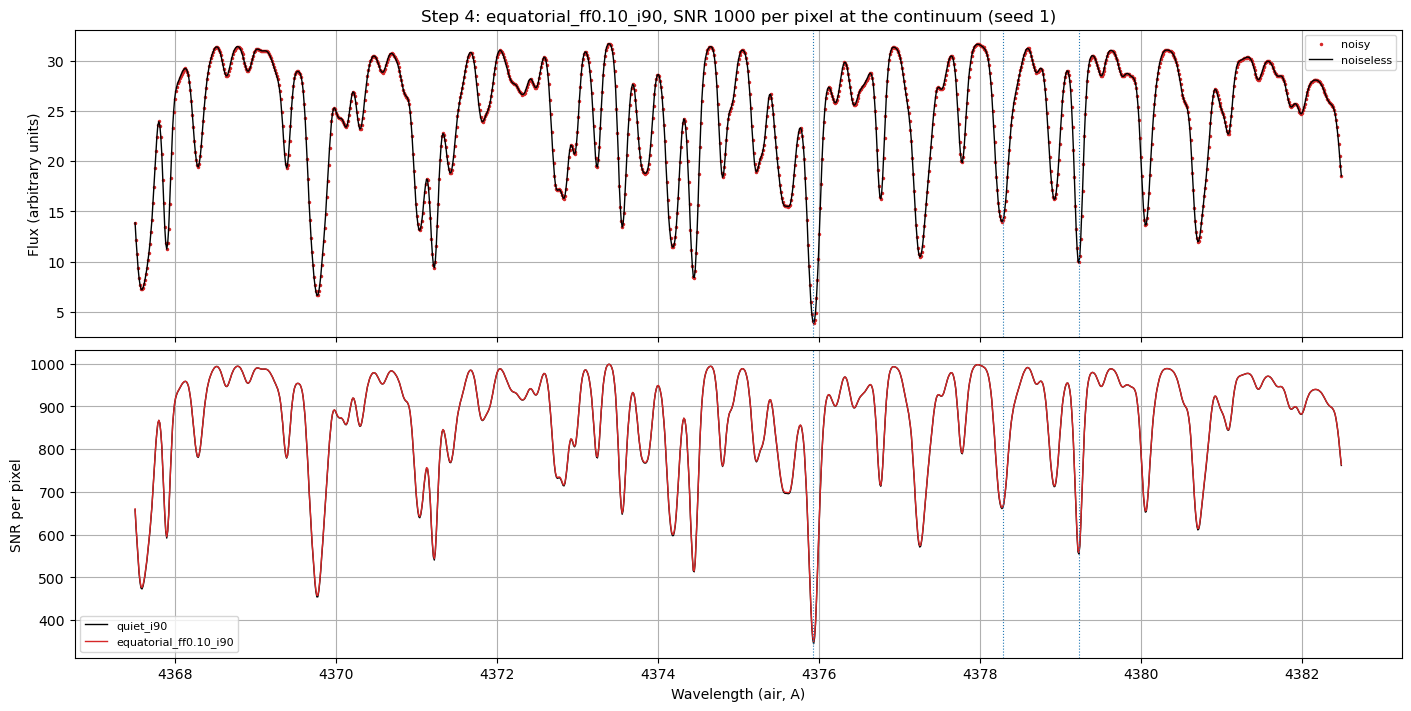

In [17]:
# ===== 4. SNR array and noise =====
# Photon noise: SNR goes as sqrt(counts), so each pixel's SNR is snr x sqrt(flux / peak flux) and line cores are
# noisier. Each spectrum gets its own noise draws (seed_active, seed_inactive).
snr_active = snr * np.sqrt(convolved_active / convolved_active.max()) 
in_window = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])
print(snr_active[in_window], convolved_active.max(), convolved_active[in_window])
snr_inactive = snr * np.sqrt(convolved_inactive / convolved_inactive.max())
noisy_active = convolved_active + np.random.default_rng(seed_active).normal(0, convolved_active / snr_active)
noisy_inactive = convolved_inactive + np.random.default_rng(seed_inactive).normal(0, convolved_inactive / snr_inactive)
print(f"SNR per pixel: {snr} at the continuum, {snr_active.min():.0f} in the deepest line core")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(wavelength[in_window], noisy_active[in_window], '.', color='tab:red', markersize=3, label='noisy')
axes[0].plot(wavelength[in_window], convolved_active[in_window], color='k', linewidth=1, label='noiseless')
axes[0].set_ylabel('Flux (arbitrary units)')
axes[0].set_title(f'Step 4: {contaminated_name}, SNR {snr} per pixel at the continuum (seed {seed_active})')
axes[1].plot(wavelength[in_window], snr_inactive[in_window], color='k', linewidth=1, label=clean_name)
axes[1].plot(wavelength[in_window], snr_active[in_window], color='tab:red', linewidth=1, label=contaminated_name)
axes[1].set_ylabel('SNR per pixel')
axes[1].set_xlabel('Wavelength (air, A)')
for ax in axes:
    mark_paper_features(ax)
    ax.grid(True)
    ax.legend(fontsize=8)
plt.show()

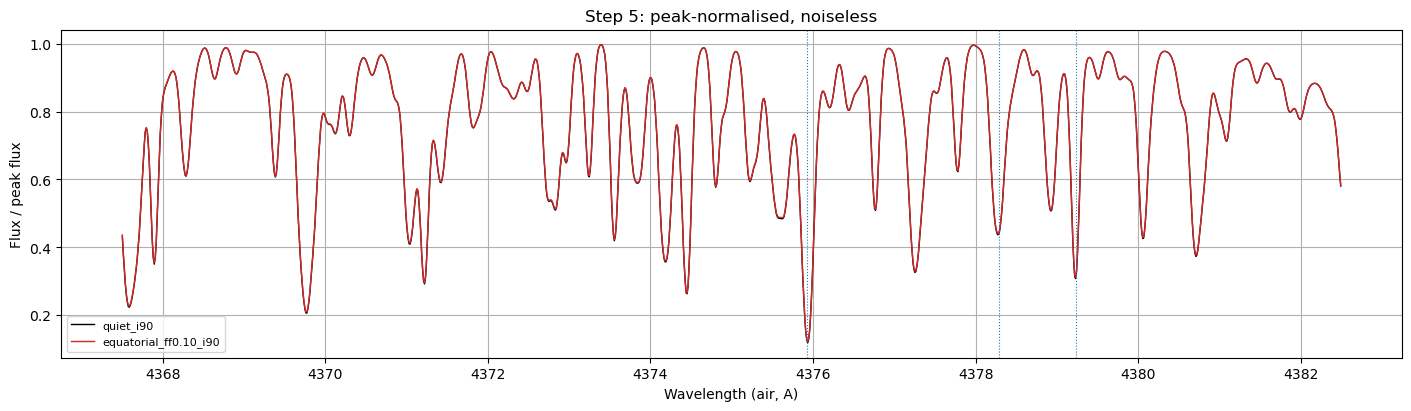

In [18]:
# ===== 5. normalise each spectrum to its peak =====
# Paper (Sec. 2.2, p. 3): "each order of these nightly or seasonal spectra was normalised to one using the peak of
# the flux". The whole window is treated as one order. Without flattening, the two peak fluxes set the zero point
# of the SRA residual.
def peak_normalised(flux):
    return flux / flux.max()


norm_active, norm_inactive = peak_normalised(noisy_active), peak_normalised(noisy_inactive)
norm_active_noiseless, norm_inactive_noiseless = peak_normalised(convolved_active), peak_normalised(convolved_inactive)

fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(wavelength[in_window], norm_inactive_noiseless[in_window], color='k', linewidth=1, label=clean_name)
ax.plot(wavelength[in_window], norm_active_noiseless[in_window], color='tab:red', linewidth=1,
        label=contaminated_name)
mark_paper_features(ax)
ax.set_xlabel('Wavelength (air, A)')
ax.set_ylabel('Flux / peak flux')
ax.set_title('Step 5: peak-normalised, noiseless')
ax.grid(True)
ax.legend(fontsize=8)
plt.show()

Fe I 4375.9 (air): truth 0.0372, observified 0.0298, noise 0.0041 (7.3 sigma)


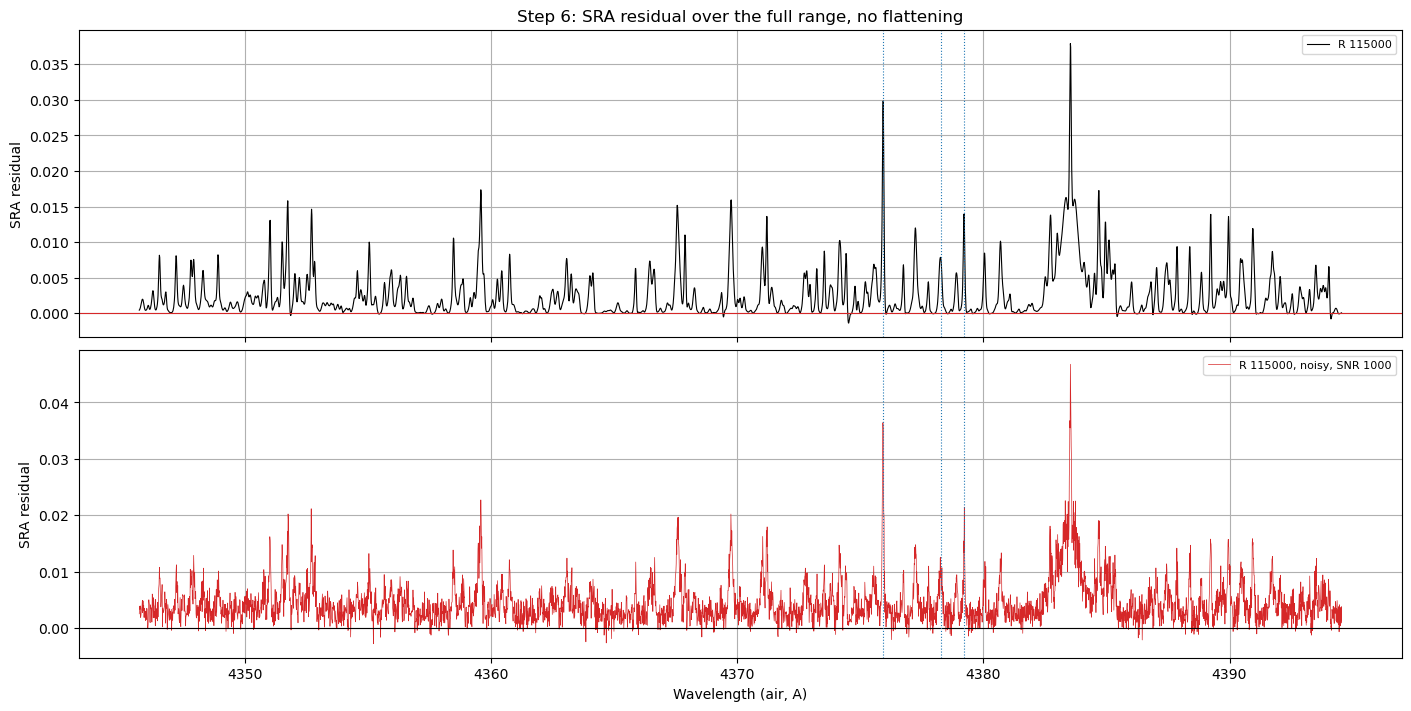

In [19]:
# ===== 6. ratio =====
# Paper (Sec. 2.2): ratio = active / low-activity template, then flattened in step 6b. SRA residual = ratio - 1.
def sra_residual(active, inactive):
    return active / inactive - 1


sra_noisy = sra_residual(norm_active, norm_inactive)
sra_noiseless = sra_residual(norm_active_noiseless, norm_inactive_noiseless)
sra_sigma = np.sqrt(1 / snr_active ** 2 + 1 / snr_inactive ** 2)   # 1-sigma noise of the ratio
truth = flux_active / flux_inactive - 1                            # native resolution, no instrument or processing

near_fe = np.abs(wavelength - paper_features['Fe I 4375.9']) < 0.1
peak = np.argmax(np.where(near_fe, sra_noiseless, -np.inf))
print(f"Fe I 4375.9 (air): truth {truth[np.abs(wavelength_native - paper_features['Fe I 4375.9']) < 0.1].max():.4f}, "
      f"observified {sra_noiseless[peak]:.4f}, noise {sra_sigma[peak]:.4f} ({sra_noiseless[peak] / sra_sigma[peak]:.1f} sigma)")

# Full range, so the slow baseline that flattening would remove is visible; noisy in its own panel so it doesn't cover it
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(wavelength, sra_noiseless, color='k', linewidth=0.8, label=f'R {resolution}')
axes[0].axhline(0, color='tab:red', linewidth=0.8)
axes[0].set_title('Step 6: SRA residual over the full range, no flattening')
axes[1].plot(wavelength, sra_noisy, color='tab:red', linewidth=0.5, label=f'R {resolution}, noisy, SNR {snr}')
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].set_xlabel('Wavelength (air, A)')
for ax in axes:
    mark_paper_features(ax)
    ax.set_ylabel('SRA residual')
    ax.grid(True)
    ax.legend(fontsize=8)
plt.show()

Continuum in the plot window, median SRA: noisy +0.00206 -> -0.00111, noiseless +0.00009 -> -0.00103
Fe I 4375.9 (air), noiseless: 0.0298 -> 0.0230


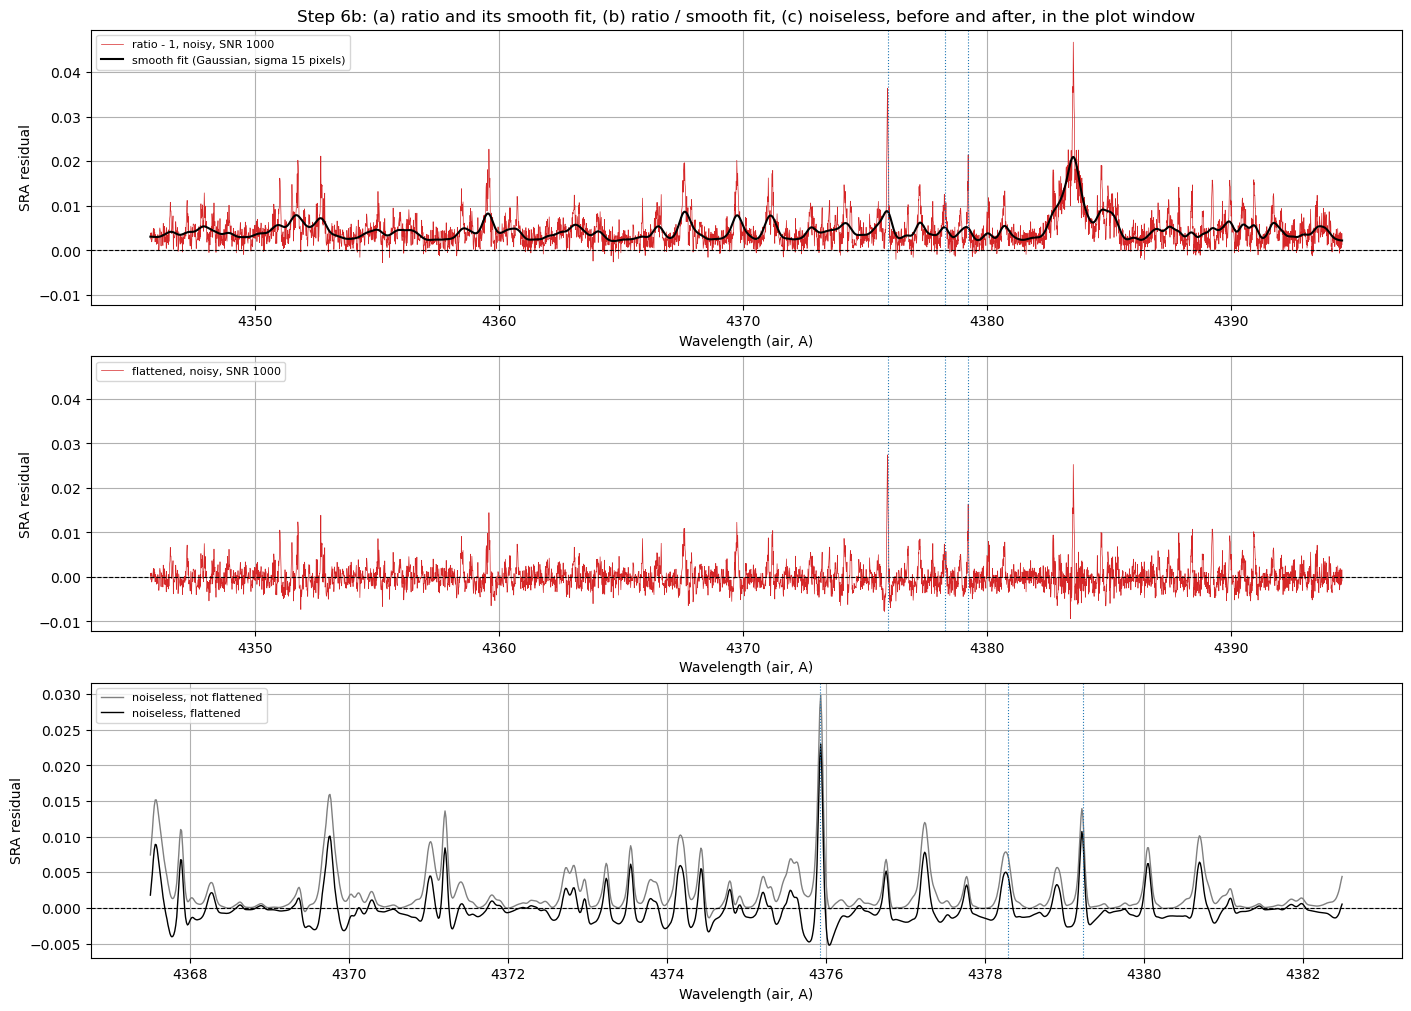

In [20]:
# ===== 6b. flatten =====
# The 15-pixel Gaussian smoothing follows only structure much wider than 15 pixels: offsets (such as the lift from
# peak-normalising noisy spectra, step 5) and slow tilts. Dividing by it removes those and keeps the narrow features
# and the noise. Where features are dense, they also raise the smooth fit, so after dividing they come out lower and
# the continuum between them dips below zero (both printed below).
# The paper does not give the filter's edge treatment; scipy's default (reflect) changes only the outer ~45 pixels.
def smooth_fit(sra):
    return gaussian_filter1d(sra + 1, flatten_sigma) - 1


def flattened(sra):
    return (sra + 1) / (smooth_fit(sra) + 1) - 1


sra_noisy_unflattened, sra_noiseless_unflattened = sra_noisy, sra_noiseless
sra_noisy, sra_noiseless = flattened(sra_noisy_unflattened), flattened(sra_noiseless_unflattened)
continuum_pixels = in_window & (norm_inactive_noiseless > 0.95)
print(f"Continuum in the plot window, median SRA: noisy {np.median(sra_noisy_unflattened[continuum_pixels]):+.5f} -> "
      f"{np.median(sra_noisy[continuum_pixels]):+.5f}, noiseless {np.median(sra_noiseless_unflattened[continuum_pixels]):+.5f} -> "
      f"{np.median(sra_noiseless[continuum_pixels]):+.5f}")
print(f"Fe I 4375.9 (air), noiseless: {sra_noiseless_unflattened[peak]:.4f} -> {sra_noiseless[peak]:.4f}")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), constrained_layout=True)
axes[0].plot(wavelength, sra_noisy_unflattened, color='tab:red', linewidth=0.5, label=f'ratio - 1, noisy, SNR {snr}')
axes[0].plot(wavelength, smooth_fit(sra_noisy_unflattened), color='k', linewidth=1.5,
             label=f'smooth fit (Gaussian, sigma {flatten_sigma} pixels)')
axes[0].set_title('Step 6b: (a) ratio and its smooth fit, (b) ratio / smooth fit, (c) noiseless, before and after, '
                  'in the plot window')
axes[1].plot(wavelength, sra_noisy, color='tab:red', linewidth=0.5, label=f'flattened, noisy, SNR {snr}')
axes[1].sharey(axes[0])
for ax in axes[:2]:
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
    ax.set_xlabel('Wavelength (air, A)')
axes[2].plot(wavelength[in_window], sra_noiseless_unflattened[in_window], color='grey', linewidth=1,
             label='noiseless, not flattened')
axes[2].plot(wavelength[in_window], sra_noiseless[in_window], color='k', linewidth=1, label='noiseless, flattened')
axes[2].axhline(0, color='k', linestyle='--', linewidth=0.8)
axes[2].set_xlabel('Wavelength (air, A)')
for ax in axes:
    mark_paper_features(ax)
    ax.set_ylabel('SRA residual')
    ax.grid(True)
    ax.legend(fontsize=8, loc='upper left')
plt.show()

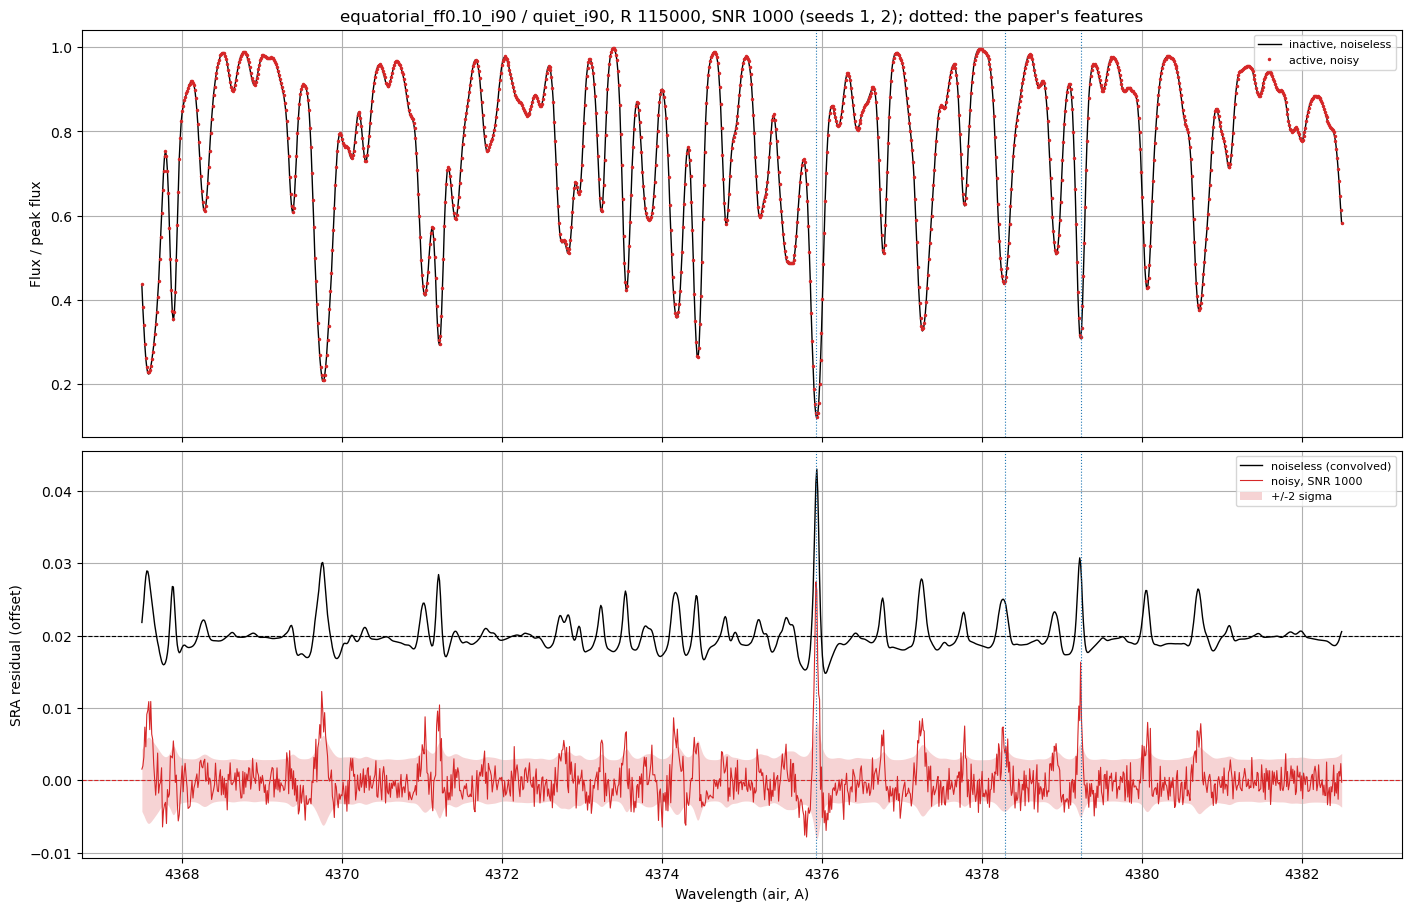

In [21]:
# ===== 7. plots =====
in_window = (wavelength >= plot_window[0]) & (wavelength <= plot_window[1])

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
axes[0].plot(wavelength[in_window], norm_inactive_noiseless[in_window], color='k', linewidth=1, label='inactive, noiseless')
axes[0].plot(wavelength[in_window], norm_active[in_window], '.', color='tab:red', markersize=3, label='active, noisy')
axes[0].set_ylabel('Flux / peak flux')
offset = 0.02   # SRA units; on a grid line, so each dashed zero line sits on the grid
axes[1].plot(wavelength[in_window], sra_noiseless[in_window] + offset, color='k', linewidth=1,
             label='noiseless (convolved)')
axes[1].plot(wavelength[in_window], sra_noisy[in_window], color='tab:red', linewidth=0.8, label=f'noisy, SNR {snr}')
axes[1].fill_between(wavelength[in_window], -2 * sra_sigma[in_window], 2 * sra_sigma[in_window],
                     color='tab:red', alpha=0.2, linewidth=0, label='+/-2 sigma')
# Each curve's own zero, so its residual can be read off against its offset
for zero_level, zero_color in ((offset, 'k'), (0, 'tab:red')):
    axes[1].axhline(zero_level, color=zero_color, linestyle='--', linewidth=0.8)
axes[1].set_ylabel('SRA residual (offset)')
axes[1].set_xlabel('Wavelength (air, A)')
for ax in axes:
    for feature_wavelength in paper_features.values():
        ax.axvline(feature_wavelength, color='tab:blue', linestyle=':', linewidth=0.8)
    ax.grid(True)
    ax.legend(fontsize=8)
axes[0].set_title(f"{contaminated_name} / {clean_name}, R {resolution}, SNR {snr} "
                  f"(seeds {seed_active}, {seed_inactive}); dotted: the paper's features")
plt.show()

SNR 200: Fe I 4375.9 (air) noiseless 0.0230, noise 0.0203 (1.1 sigma)
SNR 500: Fe I 4375.9 (air) noiseless 0.0230, noise 0.0081 (2.8 sigma)
SNR 1000: Fe I 4375.9 (air) noiseless 0.0230, noise 0.0041 (5.6 sigma)
SNR 3000: Fe I 4375.9 (air) noiseless 0.0230, noise 0.0014 (16.9 sigma)


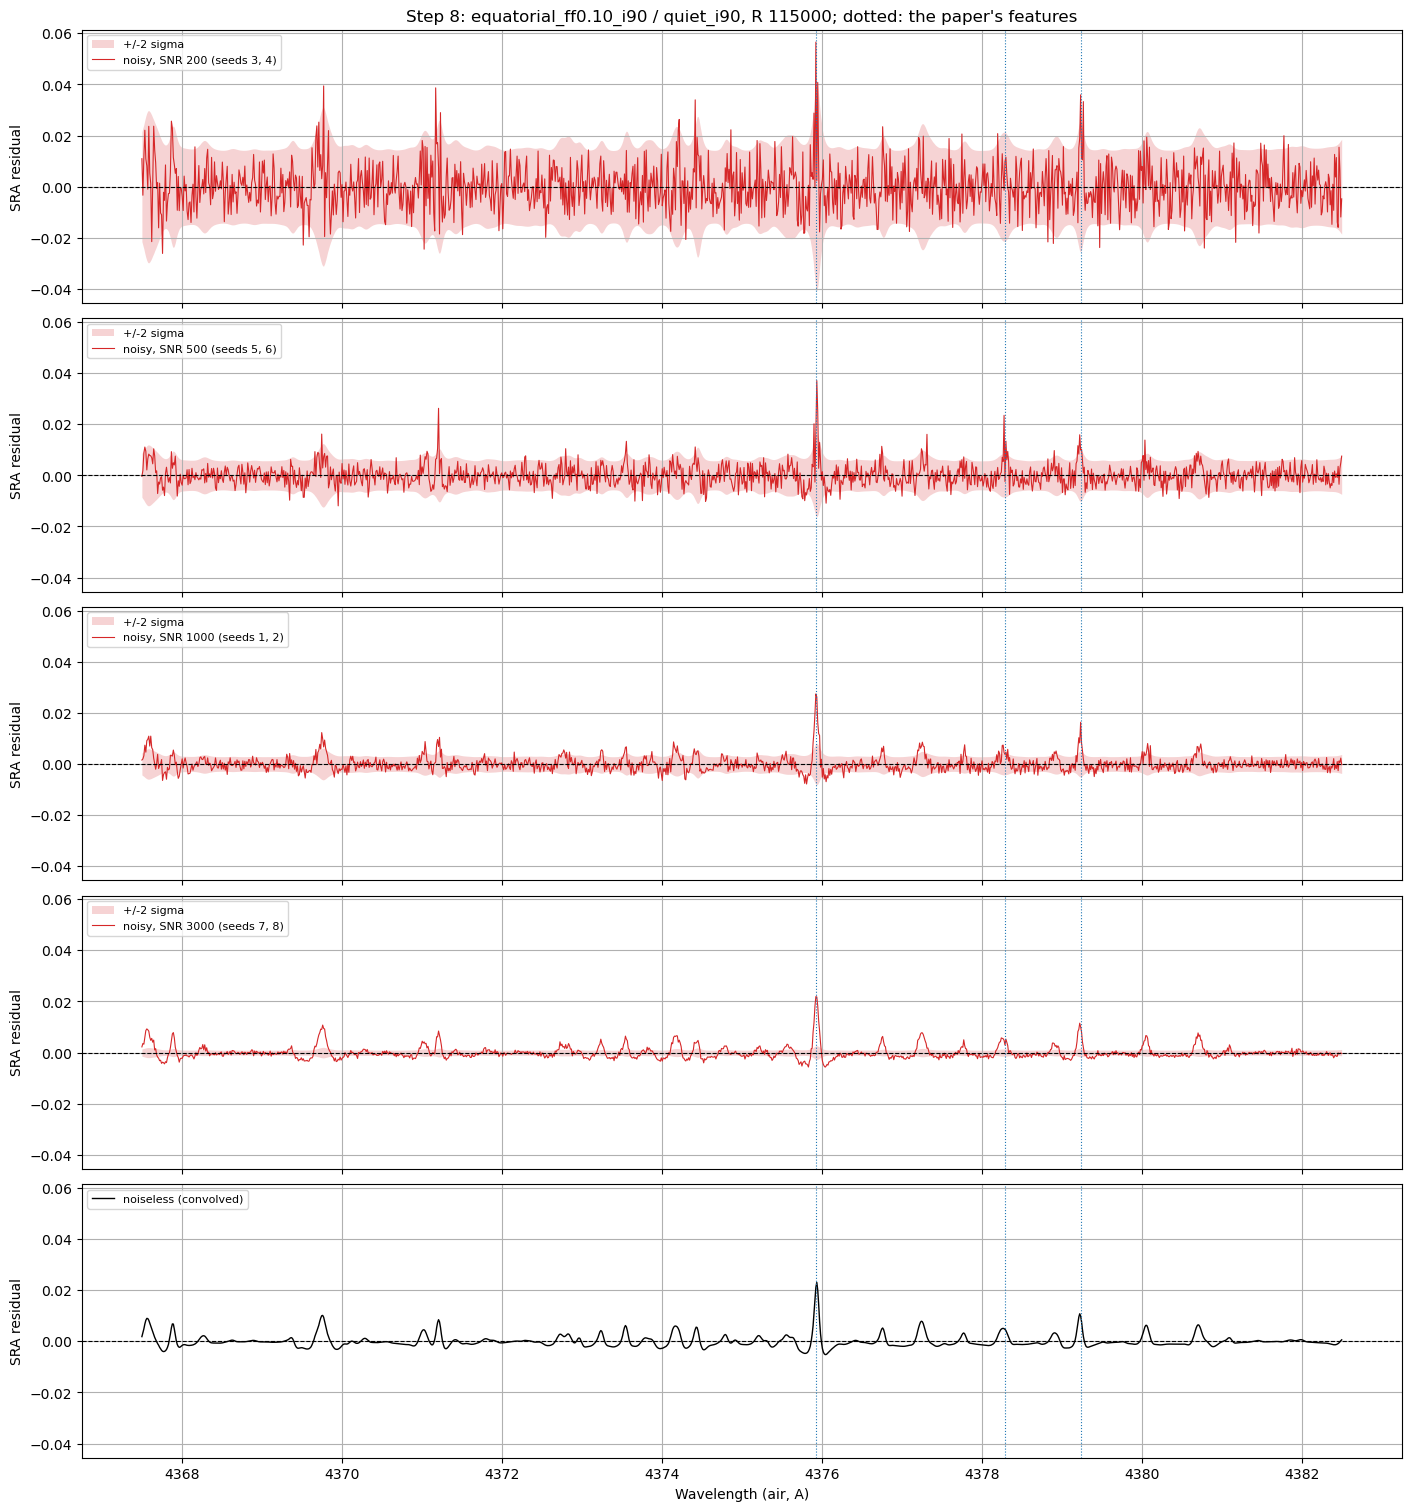

In [22]:
# ===== 8. SRA residual at SNR 200, 500, 1000 and 3000 =====
# Steps 4-6b repeated for each SNR with an independent noise draw per SNR, so panel-to-panel differences mix the SNR
# with random chance. SNR 1000 reuses the step-4 seeds, so its panel matches step 7.
comparison_seeds = {200: (3, 4), 500: (5, 6), 1000: (seed_active, seed_inactive), 3000: (7, 8)}   # snr: (active, inactive)

def noisy_spectrum(flux, snr_peak, seed):
    # Same photon-noise model as step 4: SNR per pixel = snr_peak x sqrt(flux / peak flux)
    snr_per_pixel = snr_peak * np.sqrt(flux / flux.max())
    return flux + np.random.default_rng(seed).normal(0, flux / snr_per_pixel), snr_per_pixel


# One panel per SNR, then the noiseless (convolved) SRA alone at the bottom
fig, axes = plt.subplots(len(comparison_seeds) + 1, 1, figsize=(14, 15), sharex=True, sharey=True,
                         constrained_layout=True)
for ax, (snr_peak, (seed_a, seed_i)) in zip(axes[:-1], comparison_seeds.items()):
    noisy_a, snr_a = noisy_spectrum(convolved_active, snr_peak, seed_a)
    noisy_i, snr_i = noisy_spectrum(convolved_inactive, snr_peak, seed_i)
    sra_snr = flattened(sra_residual(peak_normalised(noisy_a), peak_normalised(noisy_i)))
    sigma_snr = np.sqrt(1 / snr_a ** 2 + 1 / snr_i ** 2)   # 1-sigma noise of the ratio
    print(f"SNR {snr_peak}: Fe I 4375.9 (air) noiseless {sra_noiseless[peak]:.4f}, noise {sigma_snr[peak]:.4f} "
          f"({sra_noiseless[peak] / sigma_snr[peak]:.1f} sigma)")

    ax.fill_between(wavelength[in_window], -2 * sigma_snr[in_window], 2 * sigma_snr[in_window],
                    color='tab:red', alpha=0.2, linewidth=0, label='+/-2 sigma')
    ax.plot(wavelength[in_window], sra_snr[in_window], color='tab:red', linewidth=0.8,
            label=f'noisy, SNR {snr_peak} (seeds {seed_a}, {seed_i})')
    ax.axhline(0, color='k', linestyle='--', linewidth=0.8)
axes[-1].plot(wavelength[in_window], sra_noiseless[in_window], color='k', linewidth=1, label='noiseless (convolved)')
axes[-1].axhline(0, color='k', linestyle='--', linewidth=0.8)
for ax in axes:
    mark_paper_features(ax)
    ax.set_ylabel('SRA residual')
    ax.grid(True)
    ax.legend(fontsize=8, loc='upper left')
axes[0].set_title(f"Step 8: {contaminated_name} / {clean_name}, R {resolution}; dotted: the paper's features")
axes[-1].set_xlabel('Wavelength (air, A)')
plt.show()

In [23]:
# ===== 9. Jean's Zenodo SRA results for HD146233: what is in the file =====
# Costes et al. 2026 dataset (https://doi.org/10.5281/zenodo.18231181, v1, CC-BY-4.0). No tables: each extension is an
# image array whose header keyword DATA says what it holds. Per J. Costes (email), the errors are photon noise,
# sqrt(flux), propagated through the SRA steps; HARPS itself does not provide them.
from astropy.io import fits

zenodo_file = './jean_data/HD146233_G2V_SDAresults.fits'

with fits.open(zenodo_file, memmap=True) as zenodo:
    for extension_index, hdu in enumerate(zenodo):
        print(f"{extension_index}  {hdu.header['DATA']:<40} shape {hdu.data.shape}")
    zenodo_wavelength = zenodo[0].data   # A, (order, pixel); assumed air like the order-21 text files: not stated in the file

    # Which order is the one in target_wavelength_file? The text file drops the first pixel (step 3b)
    target_pixels = np.loadtxt(target_wavelength_file, skiprows=2, usecols=0)
    mismatch_per_order = [np.max(np.abs(order_wavelength[1:] - target_pixels)) for order_wavelength in zenodo_wavelength]
    zenodo_order = int(np.argmin(mismatch_per_order))
    print(f"\n{target_wavelength_file} is order index {zenodo_order} here "
          f"({zenodo_wavelength[zenodo_order][0]:.2f}-{zenodo_wavelength[zenodo_order][-1]:.2f} A), "
          f"max wavelength difference {mismatch_per_order[zenodo_order]:.1e} A")
    if mismatch_per_order[zenodo_order] > 1e-4:   # A
        raise ValueError(f"No order in {zenodo_file} is on the pixels of {target_wavelength_file}")
    for extension_index in (2, 4, 6):
        errors = zenodo[extension_index].data[zenodo_order]
        print(f"{zenodo[extension_index].header['DATA']:<20} order {zenodo_order}: median {np.nanmedian(errors):.5f}, "
              f"{np.isfinite(errors).sum()} finite values")

0  Wavelength                               shape (57, 4096)
1  SDATemplate                              shape (57, 4096)
2  SDATemplate error                        shape (57, 4096)
3  Seasonal SDA                             shape (57, 10, 4096)
4  Seasonal SDA error                       shape (57, 10, 4096)
5  Nightly SDA                              shape (57, 82, 4096)
6  Nightly SDA error                        shape (57, 82, 4096)
7  Seasonal BJD - 2,400,000 and logRHK      shape (2, 10)
8  Nightly BJD - 2,400,000 and logRHK       shape (2, 82)

./jean_data/Dana_SDA_HD146233_G2V_order21.txt is order index 13 here (4345.71-4394.55 A), max wavelength difference 5.0e-07 A
SDATemplate error    order 13: median 0.00147, 2604 finite values
Seasonal SDA error   order 13: median 0.00216, 26020 finite values
Nightly SDA error    order 13: median 0.00455, 213476 finite values


Jean season 0: median error at the continuum 0.00225
5.1 SNR 200: median error at the continuum 0.00718, Jean / 5.1 = 0.31
5.1 SNR 500: median error at the continuum 0.00287, Jean / 5.1 = 0.79
5.1 SNR 1000: median error at the continuum 0.00144, Jean / 5.1 = 1.57
5.1 SNR 3000: median error at the continuum 0.00048, Jean / 5.1 = 4.72


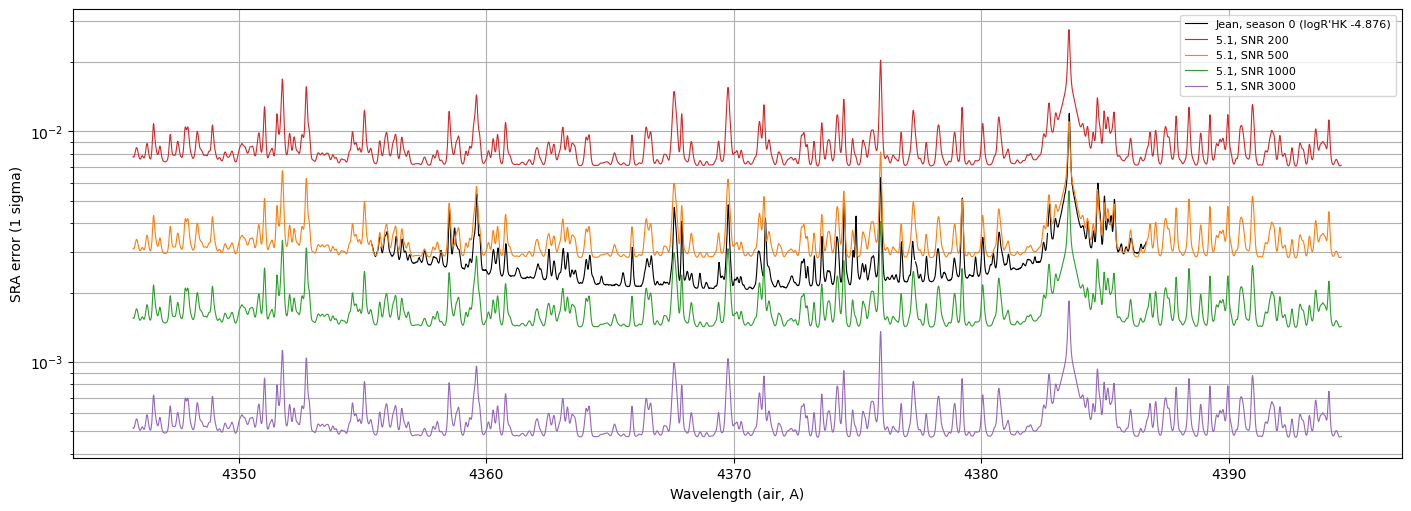

In [24]:
with fits.open(zenodo_file) as zenodo:
    season_error = zenodo[4].data[zenodo_order, 0, 1:].copy()   # first season, same 4095 pixels as wavelength
    season_logrhk = zenodo[7].data[1, 0]


def sra_sigma_model(snr_peak):
    # Same photon-noise model as steps 4 and 6: SNR per pixel = snr_peak x sqrt(flux / peak flux), then in quadrature
    snr_a = snr_peak * np.sqrt(convolved_active / convolved_active.max())
    snr_i = snr_peak * np.sqrt(convolved_inactive / convolved_inactive.max())
    return np.sqrt(1 / snr_a ** 2 + 1 / snr_i ** 2)


continuum_pixels_order = norm_inactive_noiseless > 0.95   # whole order, not just the plot window
print(f"Jean season 0: median error at the continuum {np.nanmedian(season_error[continuum_pixels_order]):.5f}")
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(wavelength, season_error, color='k', linewidth=0.8, label=f"Jean, season 0 (logR'HK {season_logrhk:.3f})")
for snr_peak, snr_color in zip(comparison_seeds, ('tab:red', 'tab:orange', 'tab:green', 'tab:purple')):
    sigma_model = sra_sigma_model(snr_peak)
    print(f"5.1 SNR {snr_peak}: median error at the continuum {np.median(sigma_model[continuum_pixels_order]):.5f}, "
          f"Jean / 5.1 = {np.nanmedian(season_error[continuum_pixels_order] / sigma_model[continuum_pixels_order]):.2f}")
    ax.plot(wavelength, sigma_model, color=snr_color, linewidth=0.8, label=f'5.1, SNR {snr_peak}')
ax.set_yscale('log')   # the SNRs span a factor of 15 in error
ax.set_xlabel('Wavelength (air, A)')
ax.set_ylabel('SRA error (1 sigma)')
ax.grid(True, which='both')
ax.legend(fontsize=8)
plt.show()


#note that Jean generates the low activity spectrum by averaging multiple seasons